# ChromData: the data model

`ChromData` is the one object every U-Chrom module reads and writes: cells › traces › spots, each spot a
3-D position of one genomic locus, all spots pointing into one shared locus axis (`bins`).  This tutorial
walks through the format 2.x model on a real chromatin-tracing dataset: how to build an object, the locus
axis, per-locus vs per-spot signals, the cell and trace tables, typed interval tables, results with
provenance, subsetting, on-demand distances and cell positions.

**Modules**: `chromdata` (`ChromData`, `chromdata.intervals`, `chromdata.results`); a few functions of
`uchrom.fea` fill a `binm` array, the trace table and a cell position set (`distance_map`,
`radius_of_gyration`, `trace_distance_matrix`, `spot_centroids`), and one analysis call
(`uc.tl.call_tads`) shows how analysis functions fill `intervals` and `results`.
**Data**: Takei et al. 2021, *Nature* 590:344 (DNA seqFISH+, 201 mouse ES cells, 20 chromosomes × 60 loci
of 25 kb): `ds.load("takei2021_mesc")` gives it as a `ChromData` — built once from the 4DN FOF-CT core
table `4DNFIHF3JCBY.csv` with its cell table `4DNFIFINA2U9.csv` and nascent-RNA spot table
`4DNFIJ52NVDV.csv` (downloaded from the 4DN data portal; reading FOF-CT is the subject of `import_fofct`),
then read from the data directory.  **Runtime**: about 15 s.
Storage on disk (`.chromdata.zarr`, backed reads, linked contact maps, the atlas) is the subject of
`chromdata_stores`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chromdata
from chromdata import ChromData
import uchrom.datasets as ds

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out") / "chromdata_basics"; OUT.mkdir(parents=True, exist_ok=True)   # tutorials/_out/ (ignored by git)

t0 = time.perf_counter()
cd = ds.load("takei2021_mesc")       # built once from the 4DN FOF-CT tables, then read from the data directory
print("chromdata", chromdata.__version__, f"| loaded in {time.perf_counter() - t0:.2f} s:")
print(cd)

chromdata 0.1.0 | loaded in 0.65 s:
ChromData: n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  cells:   ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2', 'cytoplasm_area_um2', 'rna.Eef2', 'rna.Auts2', 'rna.Bdnf', 'rna.Clu', 'rna.Cx3cr1', 'rna.Efna5', 'rna.Npy', 'rna.S100b', 'rna.Slc17a7', 'rna.Stmn2', 'rna.Zfp42', 'rna.Myc', 'rna.Ccnd2', 'rna.Mcm2', 'rna.Mki67', 'rna.Sox2', 'rna.Nes', 'rna.Cdk1', 'rna.Mtf2', 'rna.Jade1', 'rna.Cenpa', 'rna.Aurka', 'rna.Plk1', 'rna.Mdm2', 'rna.Aebp2', 'rna.Tet1', 'rna.Nodal', 'rna.Tfcp2l1', 'rna.Tdh', 'rna.Sall4', 'rna.Nanog', 'rna.Esrrb', 'rna.Pou5f1', 'rna.Klf6', 'rna.Ctgf', 'rna.Peg10', 'rna.Myh9', 'rna.Tbx3', 'rna.Otx2', 'rna.Dnmt3a', 'rna.Dnmt3b', 'rna.Lin28a', 'rna.Lin28b', 'rna.Zscan4c', 'rna.Zfp352'] (201 cells)
  points:  {'rna': 3335}
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly', 'fofct_compan

## The model at a glance

| axis | one row per | attributes |
|---|---|---|
| spots | detected locus of one trace | `coords` (n_spots × 3), `spots` (`bin_id`, `trace_id`, `cell_id`, …), `spot_tracks`, `layers` |
| bins | locus, shared by all cells | `bins` (`chrom`, `start`, `end`), `bin_tracks`, `binm`, `intervals` |
| cells | cell | `cells` (incl. cell positions), `cellm`, `cell_shapes`, `points` (RNA spots, …) |
| traces | chromatin fibre (one homolog of one chromosome) | `traces` |
| – | analysis output | `results` (with provenance), `uns` |

Pairwise distance matrices are never stored (they are per trace and O(n²)); contact maps and RNA matrices
stay in their own files and are *linked* (see `chromdata_stores`).

## Building a ChromData from a spot table

The minimum is `coords` (n_spots × 3) and a `spots` table with `trace_id` and either the loci
(`chrom`, `start`, `end`) — the locus axis `bins` is then derived — or a `bin_id` into a `bins` table you
pass.  Take the spots of the first cell as a plain table — `to_dataframe()` gives one row per spot with
its locus and `x, y, z`, here put back in the order of the original file (`spot_id`) — and build the
object by hand.

In [2]:
one = cd.get_cell("0_1").to_dataframe().sort_values("spot_id", ignore_index=True)
print("columns:", one.columns.tolist())
spots = one[["chrom", "start", "end", "trace_id", "cell_id", "spot_id"]].astype(
    {"chrom": str, "trace_id": str, "cell_id": str})                        # plain strings, as in a CSV
mini = ChromData(one[["x", "y", "z"]].to_numpy(), spots, uns={"genome_assembly": "mm10", "xyz_unit": "micron"})
mini

columns: ['chrom', 'start', 'end', 'x', 'y', 'z', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id']


ChromData: n_spots=1473, n_traces=39, n_cells=1, n_bins=953
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'spot_id', 'bin_id']
  uns:     ['genome_assembly', 'xyz_unit']

The constructor derived `bins` from the distinct loci (sorted by chromosome, start, end) and gave every spot a
`bin_id`.  Two spots of different homologs (traces `…_0` and `…_1`) at the same locus share a bin:

In [3]:
display(mini.bins.head(3))
mini.spots.head(3)

,chrom,start,end
bin_id,,,
0,chr1,135625000,135650000
1,chr1,135650000,135675000
2,chr1,135700000,135725000


,chrom,start,end,trace_id,cell_id,spot_id,bin_id
0,chr1,135625000,135650000,0_1_1_0,0_1,705144,0
1,chr1,135650000,135675000,0_1_1_0,0_1,705145,1
2,chr1,135650000,135675000,0_1_1_1,0_1,705146,1


The same object can be built from `bin_id` + `bins=`; `chrom` / `start` / `end` are then filled in from
`bins`.  Pass `bins=` whenever objects must share one locus axis — this cell alone saw only 953 of the 1,200
imaged loci.  Missing required columns fail at construction:

In [4]:
mini2 = ChromData(mini.coords, mini.spots[["bin_id", "trace_id", "cell_id", "spot_id"]], bins=mini.bins)
print("same spots:", mini2.spots_with_loci()[mini.spots.columns].equals(mini.spots))
try:
    ChromData(mini.coords, spots.drop(columns="trace_id"))
except ValueError as err:
    print("ValueError:", err)

same spots: True
ValueError: spots missing required column: 'trace_id'


## The whole dataset: `ds.load`

`ds.load("takei2021_mesc")` built `cd` (first cell above) once with `ChromData.from_fofct`, which reads
the core table and its companion tables: the cell table became `cells` (cell-table centroids are
registered as cell positions) and the RNA spot table `points["rna"]`; the `##` header lines went to
`uns`.  It wrote the object as a store in the data directory (`ds.data_dir()`) and reads that store
since; `uns["dataset"]` records how it was built.  A store holds its spots sorted by cell › trace ›
chromosome › locus, so rows come back in that order, not in the file's.

In [5]:
print(cd.n_cells, "cells,", cd.n_traces, "traces,", cd.n_spots, "spots,", cd.n_bins, "bins on", len(cd.chroms), "chromosomes")
print("uns:", {k: cd.uns[k] for k in ("genome_assembly", "xyz_unit")}, "+", [k for k in cd.uns if k not in ("genome_assembly", "xyz_unit")])
print("built by:", cd.uns["dataset"])

201 cells, 8285 traces, 316995 spots, 1200 bins on 20 chromosomes
uns: {'genome_assembly': 'GRCm38/mm10', 'xyz_unit': 'micron'} + ['fofct_header', 'fofct_companions', 'cell_spatial', 'dataset']
built by: {'name': 'takei2021_mesc', 'loader_version': 1, 'sources': ['takei', 'takei_tables']}


A trace here is one homolog of one chromosome in one cell (`Trace_ID` = `<fov>_<cell>_<chromosome>_<homolog>`).
Spots per trace and traces per cell:

In [6]:
per_trace = cd.spots.groupby("trace_id", observed=True).size()
per_cell = cd.spots.groupby("cell_id", observed=True)["trace_id"].nunique()
dup = cd.spots.duplicated(["trace_id", "bin_id"]).sum()
print(f"spots per trace: median {per_trace.median():.0f} of 60 loci (range {per_trace.min()}-{per_trace.max()})")
print(f"traces per cell: median {per_cell.median():.0f} (2 homologs x 20 chromosomes = 40)")
print(f"{dup:,} spots ({dup / cd.n_spots:.0%}) repeat a locus already detected in the same trace")

spots per trace: median 39 of 60 loci (range 1-154)
traces per cell: median 41 (2 homologs x 20 chromosomes = 40)
35,432 spots (11%) repeat a locus already detected in the same trace


## The locus axis: `bins` and `spots.bin_id`

`bins` has one row per locus (index `bin_id`), shared by every cell; each spot points at one bin.  The
`chrom` / `start` / `end` columns of `spots` are derived from `bins` (they are not stored on disk);
`spots_with_loci()` is the stable way to get them.  `chrom`, `trace_id` and `cell_id` are categoricals.

In [7]:
display(cd.bins.groupby("chrom", observed=True).size().describe()[["count", "min", "max"]].rename("loci per chromosome").to_frame().T)
print({c: f"category ({len(t.categories)} values)" if isinstance(t, pd.CategoricalDtype) else str(t)
       for c, t in cd.spots.dtypes.items()})
as_object = cd.spots.astype({c: object for c in ("chrom", "trace_id", "cell_id")})
print(f"spots table: {cd.spots.memory_usage(deep=True).sum() / 1e6:.1f} MB with categoricals, "
      f"{as_object.memory_usage(deep=True).sum() / 1e6:.1f} MB with Python strings")

,count,min,max
loci per chromosome,20.0,60.0,60.0


{'chrom': 'category (20 values)', 'start': 'int64', 'end': 'int64', 'trace_id': 'category (8285 values)', 'spot_id': 'int64', 'cell_id': 'category (201 values)', 'extra_cell_roi_id': 'int64', 'bin_id': 'int64'}


spots table: 14.4 MB with categoricals, 64.6 MB with Python strings


To change loci, edit `cd.bins` (or edit the spot loci and call `cd.rebuild_bins()`); the derived spot
columns cannot disagree with `bins` — the constructor checks it.

## Per-locus and per-spot signals: `bin_tracks`, `spot_tracks`, `binm`

A value that belongs to a locus (bulk ChIP, GC content, a detection rate) is a column of `bin_tracks`
(n_bins rows); a value measured on one spot (IF intensity, a per-spot distance) is a column of
`spot_tracks` (n_spots rows).  Two real examples: the fraction of traces in which each locus was detected,
and each spot's distance to the centre of its trace.

In [8]:
chrom_of_bin = cd.bins["chrom"].astype(str)
traces_per_chrom = cd.spots.groupby("chrom", observed=True)["trace_id"].nunique()
traces_per_bin = cd.spots.groupby("bin_id")["trace_id"].nunique().reindex(range(cd.n_bins), fill_value=0)
cd.bin_tracks["detection_rate"] = traces_per_bin.to_numpy() / chrom_of_bin.map(traces_per_chrom).to_numpy()

trace_code = cd.spots["trace_id"].cat.codes.to_numpy()
centre = pd.DataFrame(cd.coords).groupby(trace_code).transform("mean").to_numpy()
cd.spot_tracks["dist_to_trace_centre_um"] = np.linalg.norm(cd.coords - centre, axis=1)

print(cd.track_names())
print(f"detection rate per locus: median {cd.bin_tracks['detection_rate'].median():.2f} "
      f"(range {cd.bin_tracks['detection_rate'].min():.2f}-{cd.bin_tracks['detection_rate'].max():.2f})")
cd.tracks_spot_view().head(3)

{'bin': ['detection_rate'], 'spot': ['dist_to_trace_centre_um']}
detection rate per locus: median 0.57 (range 0.01-0.80)


,detection_rate,dist_to_trace_centre_um
0,0.440191,0.369569
1,0.533493,0.377620
2,0.468900,0.386628


`tracks_spot_view()` broadcasts the bin tracks to the spots (through `bin_id`) next to the spot tracks — the
view analysis code often wants.  (The 1.x attribute `cd.tracks` is a deprecated alias of that view; new
code uses `bin_tracks` / `spot_tracks`.)

`binm` holds per-locus arrays with more than one value per bin.  Each chromosome here has 60 loci, so the
population median distance map of a chromosome fits as rows of a `(n_bins, 60)` array: row *i* holds the
median distance of locus *i* to every locus of its chromosome.  `uchrom.fea.distance_map` gives each
chromosome's map (`observed=False`: rows for all its bins; the `bin_id` of every row in `.bins`);
`duplicates="mean"` averages the spots of a trace that share a locus (11 % of the spots here) — what
`uchrom.im.merge_duplicate_spots` does to the whole object.

In [9]:
import uchrom.fea as fea

t0 = time.perf_counter()
med = np.full((cd.n_bins, 60), np.nan)
for chrom in cd.chroms:
    dm = fea.distance_map(cd, chrom, observed=False, duplicates="mean")   # population median over the traces
    med[dm.bins["bin_id"].to_numpy()] = dm.matrix
cd.binm["median_distance_um"] = med
print(f"{cd.n_spots:,} spots -> {cd.n_spots - dup:,} after averaging repeats; binm['median_distance_um'] {med.shape} in "
      f"{time.perf_counter() - t0:.1f} s; neighbouring loci (25 kb apart): median "
      f"{np.nanmedian(np.diagonal(med.reshape(20, 60, 60), 1, 1, 2)):.2f} um")

316,995 spots -> 281,563 after averaging repeats; binm['median_distance_um'] (1200, 60) in 1.5 s; neighbouring loci (25 kb apart): median 0.18 um


## Cells, traces, layers and points

`cells` is indexed by `cell_id`; here it holds the cell table (nucleus area, mRNA counts per gene as
`rna.<gene>`, the authors' QC flag `keep1`).  `cellm` holds per-cell arrays whose rows follow `cells` —
e.g. a PCA of the log-normalised mRNA counts:

In [10]:
genes = [c for c in cd.cells.columns if c.startswith("rna.")]
counts = cd.cells[genes].to_numpy(float)
logx = np.log1p(counts / counts.sum(1, keepdims=True) * 1e4)
u, s, _ = np.linalg.svd(logx - logx.mean(0), full_matrices=False)
cd.cellm["rna_pca"] = u[:, :10] * s[:10]
print(f"{len(genes)} genes; cellm:", {k: v.shape for k, v in cd.cellm.items()},
      f"; PC1-2 explain {(s[:2] ** 2).sum() / (s ** 2).sum():.0%} of the variance")
cd.cells[["keep1", "nucleus_area_um2", "rna.Nanog", "rna.Zfp42"]].head(3)

45 genes; cellm: {'rna_pca': (201, 10)} ; PC1-2 explain 35% of the variance


,keep1,nucleus_area_um2,rna.Nanog,rna.Zfp42
cell_id,,,,
0_1,0,242.161034,0.0,21.0
0_2,0,158.668204,1.0,95.0
0_3,0,203.735236,0.0,41.0


`traces` is the per-trace table, indexed by `trace_id`.  We fill it from the data: chromosome, homolog
(the last field of the id: 0 or 1 for most traces, -1, 2 or 3 for some, as deposited), number of spots and
radius of gyration (`fea.radius_of_gyration`: the root mean square distance of the spots to their centre;
NaN for a trace with one spot).

In [11]:
g = cd.spots.astype({"trace_id": str, "chrom": str})
traces = g.groupby("trace_id").agg(chrom=("chrom", "first"), n_spots=("bin_id", "size"))
traces["rg_um"] = fea.radius_of_gyration(cd)
traces["homolog"] = traces.index.str.rsplit("_", n=1).str[1].astype(int)
cd.traces = traces
print(cd.traces["homolog"].value_counts().to_dict())
cd.traces.head(3)

{0: 3987, 1: 3551, -1: 659, 2: 83, 3: 5}


,chrom,n_spots,rg_um,homolog
trace_id,,,,
0_10_10_0,chr10,33,0.499358,0
0_10_10_1,chr10,45,0.373785,1
0_10_11_0,chr11,50,0.336504,0


`layers` are alternative coordinate sets with the shape of `coords` (raw / drift-corrected / a second
model).  `points` are non-genomic 3-D points in the same frame, here the 3,335 nascent-RNA spots, linked
to cells by `cell_id`.

In [12]:
cd.layers["trace_centred"] = cd.coords - centre
print({k: v.shape for k, v in cd.layers.items()})
print(len(cd.points["rna"]), "RNA spots; most frequent:", cd.points["rna"]["gene"].value_counts().head(3).to_dict())
cd.points["rna"][["x", "y", "z", "gene", "cell_id"]].head(3)

{'trace_centred': (316995, 3)}
3335 RNA spots; most frequent: {'Lgr4': 457, 'Actb': 454, 'Rpl5': 359}


,x,y,z,gene,cell_id
0,169.853,26.619,3.386,Auts2,0_1
1,152.599,24.696,2.371,Auts2,0_2
2,32.609,78.165,3.294,Auts2,0_10


## Interval tables: `intervals`

`cd.intervals` maps a key to an `IntervalTable`, a DataFrame with a declared `kind`:
`domain` (`chrom, start, end`: TADs, domains), `pair` (`chrom1 … end2`: loops), `peak` and `segment`
(`… label`: compartments).  Tables are validated when stored.  The imaged regions make a small `domain` table:

In [13]:
regions = cd.bins.groupby("chrom", observed=True).agg(start=("start", "min"), end=("end", "max")).reset_index()
cd.intervals.add("regions.imaged", regions, kind="domain")
print(cd.intervals)
try:
    cd.intervals.add("broken", regions.assign(end=regions["start"] - 1), kind="domain")
except ValueError as err:
    print("ValueError:", err)
cd.intervals["regions.imaged"].head(3)

IntervalStore({'regions.imaged': <domain, 20 rows>})
ValueError: domain intervals must satisfy end >= start


,chrom,start,end
0,chr1,135600000,137100000
1,chr10,75400000,76900000
2,chr11,97425000,98925000


## Results with provenance: `results`

`cd.results` is a `ResultsStore`: `cd.results[key]` is the value, `cd.results.record(key)` the value with
its provenance (producing function, parameters, inputs, package version, time).  Values must be storable
(DataFrame / Series, numeric array, dict of those, JSON scalars); anything else fails at assignment, not at
`write()`.

In [14]:
long = cd.traces[cd.traces["n_spots"] >= 30]
rg = long.groupby("chrom")["rg_um"].median()
cd.results.set("rg.median_by_chrom", rg, function="tutorials/chromdata_basics.ipynb",
               params={"min_spots": 30}, inputs={"n_traces": len(long)})
print(cd.results)
print(cd.results.record("rg.median_by_chrom").provenance)
print(f"median Rg per chromosome (1.5 Mb regions): {rg.min():.2f}-{rg.max():.2f} um")
try:
    cd.results["not_storable"] = {1, 2, 3}
except TypeError as err:
    print("TypeError:", str(err)[:90], "...")

ResultsStore({'rg.median_by_chrom': <table>})
{'kind': 'table', 'function': 'tutorials/chromdata_basics.ipynb', 'params': {'min_spots': 30}, 'inputs': {'n_traces': 5815}, 'uchrom_version': '0.3.0.dev0', 'created_utc': '2026-10-14T06:13:52+00:00'}
median Rg per chromosome (1.5 Mb regions): 0.29-0.44 um
TypeError: results['not_storable']: cannot store a value of type set in cd.results. Supported: DataFr ...


Analysis functions of `uchrom` follow one convention: they store their table under `key_added`
(`"tads.arcfish"` here) with provenance, and interval-like outputs also appear in `cd.intervals` (the same
object, typed, with `source_result` pointing back to the record).  ArcFISH TAD calling on chr3 (window ±100 kb,
ArcFISH's default): level 0 of the table is the finest partition, each higher level one domain merged by
removing the next weakest boundary:

In [15]:
import uchrom as uc

t0 = time.perf_counter()
tads = uc.tl.call_tads(cd, chrom="chr3", device="cpu")
print(f"call_tads: {time.perf_counter() - t0:.1f} s, {len(tads)} domains over {tads['level'].nunique()} levels")
rec = cd.results.record("tads.arcfish")
print(cd.intervals)
print("kind:", cd.intervals["tads.arcfish"].kind, "| source_result:", cd.intervals["tads.arcfish"].source_result)
print("function:", rec.function, "| params:", rec.params)
tads[tads["level"] == 0]

call_tads: 4.6 s, 7 domains over 4 levels
IntervalStore({'regions.imaged': <domain, 20 rows>, 'tads.arcfish': <domain, 7 rows>})
kind: domain | source_result: tads.arcfish
function: uchrom.strc.tad.call_tads_by_pval | params: {'window_bp': 100000.0, 'fdr_cutoff': 0.1, 'method': 'pval', 'hierarchical': True, 'min_tad_size': 0.0, 'max_levels': None, 'prominence': None, 'distance': None, 'k_sigma': 4.0, 'frac': 0.1}


,chrom,start,end,level,start1,end1,start2,end2,stat1,stat2
0,chr3,7675000,8575000,0,7675000,7700000,8575000,8600000,NaN,4.903416e+10
1,chr3,8575000,8900000,0,8575000,8600000,8900000,8925000,4.903416e+10,1.483528e+05
2,chr3,8900000,9075000,0,8900000,8925000,9075000,9100000,1.483528e+05,3.454916e+03
3,chr3,9075000,9300000,0,9075000,9100000,9300000,9325000,3.454916e+03,NaN


`IntervalTable.to_bins` projects intervals onto the locus axis — for example the level-0 domain of every
chr3 locus as a bin track (-1 where no domain overlaps):

In [16]:
level0 = cd.intervals["tads.arcfish"].query("level == 0")
cd.bin_tracks["tad_chr3_level0"] = level0.to_bins(cd.bins, how="id").to_numpy()
cd.bin_tracks.loc[chrom_of_bin == "chr3", "tad_chr3_level0"].value_counts().sort_index().to_dict()

{-1: 1, 0: 30, 1: 13, 2: 7, 3: 9}

## Subsetting: `get_cell`, `get_cells`, `get_trace`, `get_chrom`, `cd[rows]`

Every subset is a new `ChromData` (the original is not modified).  Cell- and trace-level tables follow the
spots (`cells`, `cellm`, `traces`, `points`), the locus axis does not: `bins` and the per-locus data are kept
whole, so subsets of one dataset always share one axis.

In [17]:
def summary(name, x):
    return {"subset": name, "n_spots": x.n_spots, "n_traces": x.n_traces, "n_cells": x.n_cells,
            "traces rows": len(x.traces), "rna points": len(x.points["rna"]),
            "n_bins": x.n_bins}

qc = cd.cells.index[cd.cells["keep1"] == 1]
subsets = {
    "cd": cd,
    'cd.get_cell("0_1")': cd.get_cell("0_1"),
    "cd.get_cells(keep1 == 1)": cd.get_cells(qc),
    'cd.get_trace("0_1_3_0")': cd.get_trace("0_1_3_0"),
    'cd.get_chrom("chr3")': cd.get_chrom("chr3"),
    "cd[dist to centre < 0.5 um]": cd[cd.spot_tracks["dist_to_trace_centre_um"].to_numpy() < 0.5],
    "cd[:1000]": cd[:1000],
}
pd.DataFrame([summary(k, v) for k, v in subsets.items()]).set_index("subset")

,n_spots,n_traces,n_cells,traces rows,rna points,n_bins
subset,,,,,,
cd,316995,8285,201,8285,3335,1200
"cd.get_cell(""0_1"")",1473,39,1,39,2,1200
cd.get_cells(keep1 == 1),256148,6293,151,6293,2890,1200
"cd.get_trace(""0_1_3_0"")",40,1,1,1,2,1200
"cd.get_chrom(""chr3"")",18150,408,201,408,3335,1200
cd[dist to centre < 0.5 um],274318,8209,201,8209,3335,1200
cd[:1000],1000,27,1,27,2,1200


`columns=` selects the spot-aligned columns to carry: `columns="coords"` keeps coordinates and the key
columns only (on a backed store this decides what is read from disk, see `chromdata_stores`):

In [18]:
lean = cd.get_cell("0_1", columns="coords")
print("spots:", list(lean.spots.columns), "| spot tracks:", list(lean.spot_tracks.columns), "| layers:", list(lean.layers))

spots: ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id'] | spot tracks: [] | layers: []


## Distances on demand: `compute_distances`

`cd.compute_distances(trace_id=...)` returns the pairwise distances of one trace's spots;
`uchrom.fea.trace_distance_matrix` places them on every locus of the trace's chromosome (NaN where the trace
has no spot), the axis of the population map.  Below, the most complete chr3 trace without repeated loci,
next to the population median map from `binm` with the level-0 ArcFISH domains.

trace 1_13_3_1: 46 spots, distance matrix (46, 46)


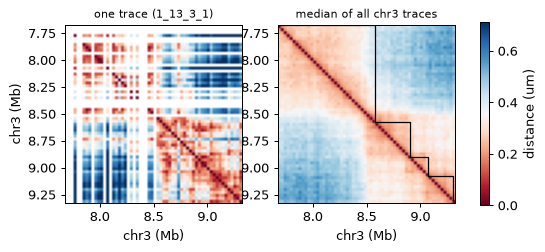

In [19]:
chr3 = subsets['cd.get_chrom("chr3")']
stats = chr3.spots.groupby("trace_id", observed=True)["bin_id"].agg(["size", "nunique"])
tid = stats[stats["size"] == stats["nunique"]]["size"].idxmax()
d = cd.compute_distances(trace_id=tid)
single, loci = fea.trace_distance_matrix(cd, tid)          # 60 x 60: the chr3 loci
ids = loci["bin_id"].to_numpy()
print(f"trace {tid}: {d.shape[0]} spots, distance matrix {d.shape}")

mb = cd.bins.loc[ids, "start"].to_numpy() / 1e6
ext = [mb[0], mb[-1] + 0.025, mb[-1] + 0.025, mb[0]]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
for ax, m, title in [(axes[0], single, f"one trace ({tid})"), (axes[1], cd.binm["median_distance_um"][ids], "median of all chr3 traces")]:
    im = ax.imshow(m, cmap="RdBu", vmin=0, vmax=np.nanpercentile(cd.binm["median_distance_um"][ids], 98) * 1.3, extent=ext)
    ax.set_title(title, fontsize=9); ax.set_xlabel("chr3 (Mb)")
for _, r in level0.iterrows():
    a, b = r["start"] / 1e6, r["end"] / 1e6
    axes[1].plot([a, b, b], [a, a, b], color="k", lw=1)
axes[0].set_ylabel("chr3 (Mb)")
fig.colorbar(im, ax=axes, shrink=0.8, label="distance (um)")
plt.show()

## Cell positions: `cell_positions`, `set_cell_positions`

Where a cell sits is cell-level data: `cells` columns (`centroid_x`, `centroid_y` [, `centroid_z`]) plus a
record in `uns["cell_spatial"]` that says what they are (unit, frame, measured or inferred, source).
`from_fofct` registered the cell-table centroids:

In [20]:
pos = cd.cell_positions()
print(pos.attrs["cell_spatial"])
pos.head(3)

{'x_col': 'centroid_x', 'y_col': 'centroid_y', 'ndim': 2, 'status': 'measured', 'unit': 'micron', 'source': 'FOF-CT cell table Cent_ROI_x / Cent_ROI_y [/ Cent_ROI_z]'}


,x,y
cell_id,,
0_1,170.079,18.531
0_2,155.510,26.151
0_3,25.481,34.890


The record does not say yet which frame the centroids are in.  The DNA spots give an independent estimate —
the mean of each cell's spots, `fea.spot_centroids` — which we store as a second position set (3-D, `inferred`, with its source).
Cell ids start with the field of view, so positions are local to a FOV (`region_col="fov"`).

In [21]:
cd.cells["fov"] = cd.cells.index.str.split("_").str[0]
spot_mean = fea.spot_centroids(cd, by="cell", stat="mean")        # x, y, z per cell
cd.set_cell_positions(spot_mean, key="dna_mean", unit="micron", frame="fov", region_col="fov",
                      in_coords_frame=True, status="inferred", source="mean of the cell's DNA seqFISH+ spots",
                      method="mean")
both = cd.cell_positions().join(cd.cell_positions("dna_mean"), rsuffix="_dna")
offset = np.hypot(both["x"] - both["x_dna"], both["y"] - both["y_dna"])
radius = np.sqrt(cd.cells["nucleus_area_um2"] / np.pi)
print(f"cell-table centroid vs DNA-spot mean: median {offset.median():.2f} um (max {offset.max():.2f}); "
      f"nucleus radius median {radius.median():.1f} um")
print("position sets:", list(cd.uns["cell_spatial"]), "| new columns:", [c for c in cd.cells.columns if c.startswith("dna_mean")])

cell-table centroid vs DNA-spot mean: median 0.50 um (max 1.58); nucleus radius median 7.4 um
position sets: ['default', 'dna_mean'] | new columns: ['dna_mean_centroid_x', 'dna_mean_centroid_y', 'dna_mean_centroid_z']


The two agree to half a micron, well inside a nucleus, so the cell-table centroids share the frame of
`coords`.  Re-registering the existing columns records that (`positions=None, columns=[...]`):

{'x_col': 'centroid_x', 'y_col': 'centroid_y', 'ndim': 2, 'unit': 'micron', 'frame': 'fov', 'region_col': 'fov', 'in_coords_frame': True, 'status': 'measured', 'source': 'FOF-CT cell table Cent_ROI_x / Cent_ROI_y'}


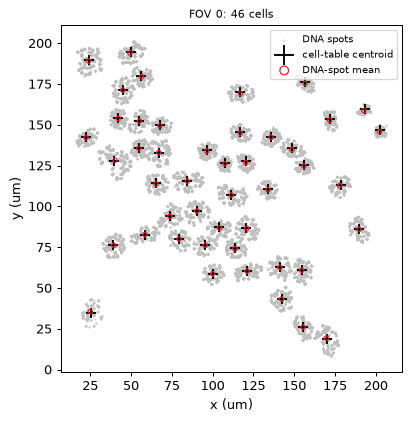

In [22]:
cd.set_cell_positions(columns=["centroid_x", "centroid_y"], unit="micron", frame="fov", region_col="fov",
                      in_coords_frame=True, source="FOF-CT cell table Cent_ROI_x / Cent_ROI_y")
print(cd.cell_positions().attrs["cell_spatial"])

fov0 = cd.cells.index[cd.cells["fov"] == "0"]
sub = cd.get_cells(fov0)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(sub.coords[:, 0], sub.coords[:, 1], s=0.05, c="0.75", rasterized=True, label="DNA spots")
p = cd.cell_positions().loc[fov0]; q = cd.cell_positions("dna_mean").loc[fov0]
ax.scatter(p["x"], p["y"], marker="+", s=60, c="k", label="cell-table centroid")
ax.scatter(q["x"], q["y"], s=12, facecolors="none", edgecolors="C3", label="DNA-spot mean")
ax.set_aspect("equal"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
ax.set_title(f"FOV 0: {len(fov0)} cells", fontsize=9); ax.legend(fontsize=8, markerscale=2, loc="upper right")
plt.show()

## Export and a round trip

`to_dataframe()` gives the flat structure table (one row per spot: loci, x, y, z and the spot columns),
`to_anndata()` the cell-level part (`cells` as `obs`, `cellm` as `obsm`), `to_fofct()` a FOF-CT table.
`write()` keeps everything; reading the store back returns every piece added above.

In [23]:
display(cd.to_dataframe().head(3))
adata = cd.to_anndata()
print("to_anndata:", adata.shape, "obsm:", list(adata.obsm))

path = OUT / "takei2021_basics.chromdata.zarr"
cd.write(path)
back = ChromData.read(path)
checks = {
    "bin_tracks": back.bin_tracks.equals(cd.bin_tracks),
    "binm": np.array_equal(back.binm["median_distance_um"], cd.binm["median_distance_um"], equal_nan=True),
    "cellm": np.array_equal(back.cellm["rna_pca"], cd.cellm["rna_pca"]),
    "traces": back.traces.sort_index().equals(cd.traces.sort_index()),
    "intervals": sorted(back.intervals) == sorted(cd.intervals),
    "results + provenance": back.results.record("tads.arcfish").provenance == rec.provenance,
    "cell positions": back.cell_positions("dna_mean").equals(cd.cell_positions("dna_mean")),
    "spot tracks (sorted by spot_id)": np.allclose(
        back.spot_tracks["dist_to_trace_centre_um"].to_numpy()[np.argsort(back.spots["spot_id"].to_numpy())],
        cd.spot_tracks["dist_to_trace_centre_um"].to_numpy()[np.argsort(cd.spots["spot_id"].to_numpy())]),
}
print(path, checks)

,chrom,start,end,x,y,z,trace_id,spot_id,cell_id,extra_cell_roi_id
0,chr10,75425000,75450000,175.054,22.503,3.261,0_1_10_0,705835,0_1,0
1,chr10,75450000,75475000,175.149,22.462,2.723,0_1_10_0,705837,0_1,0
2,chr10,75475000,75500000,175.003,22.659,3.298,0_1_10_0,705839,0_1,0


to_anndata: (201, 0) obsm: ['rna_pca', 'spatial']


_out/chromdata_basics/takei2021_basics.chromdata.zarr {'bin_tracks': True, 'binm': True, 'cellm': True, 'traces': True, 'intervals': True, 'results + provenance': True, 'cell positions': True, 'spot tracks (sorted by spot_id)': True}


## Next steps

- `chromdata_stores` — the `.chromdata.zarr` store: row order, backed reads of one cell or chromosome,
  streaming writes, linked contact maps and AnnData, embedded copies and the public atlas over HTTP.
- `import_fofct` — more on FOF-CT import and export.
- `tad_calling`, `loop_calling`, `compartment` — the structure callers that fill `intervals` and `results`.
- `fish_imputation` — filling in undetected loci (`uchrom.pp.impute`).